# 07 - Fairness and Business Impact

## Ziel
In diesem Notebook analysieren wir, ob ein Kreditrisiko-Modell nicht nur gute Vorhersagen liefert, sondern auch faire und wirtschaftlich sinnvolle Entscheidungen trifft.

## Fragestellungen
- Werden bestimmte Gruppen seltener genehmigt?
- Gibt es Unterschiede bei Fehlerraten zwischen Gruppen?
- Wie hoch ist der wirtschaftliche Nutzen oder Schaden der Modellentscheidungen?
- Wie verändert sich Profitabilität und Fairness bei unterschiedlichen Schwellenwerten?
- Gibt es Personen mit hohem Einkommen, aber schwachem Score, die möglicherweise unnötig ausgeschlossen werden?

In [2]:
import warnings
warnings.filterwarnings("ignore")

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. CSV-Datei hochladen
Bitte lade hier deine bereinigte Datendatei hoch, die die für das Modell benötigten Spalten enthält.

In [3]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

try:
    df = pd.read_csv(io.BytesIO(uploaded[file_name]), sep=",")
    if df.shape[1] == 1:
        df = pd.read_csv(io.BytesIO(uploaded[file_name]), sep=";")
except:
    df = pd.read_csv(io.BytesIO(uploaded[file_name]), sep=";")

print("Datei geladen:", file_name)
print("Shape:", df.shape)
print("\nSpalten:")
print(df.columns.tolist())

df.head()

Saving synthetic_schufa_dataset.csv to synthetic_schufa_dataset.csv
Datei geladen: synthetic_schufa_dataset.csv
Shape: (10000, 21)

Spalten:
['age', 'net_income', 'employment_status', 'marital_status', 'dependents', 'monthly_expenses', 'existing_loans', 'credit_amount', 'debt_to_income', 'late_payments', 'hard_inquiries', 'credit_history_years', 'negative_entry', 'collection_cases', 'bank_balance', 'liquidity_ratio', 'old_score', 'new_score', 'credit_approved_old_system', 'credit_approved_new_system', 'default']


,age,net_income,employment_status,marital_status,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,hard_inquiries,credit_history_years,negative_entry,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,credit_approved_old_system,credit_approved_new_system,default
0,56,"1,777.1400",selbstständig,verheiratet,0,855.6400,2,"8,894.4000",0.4200,0,1,9.2000,0,0,"4,301.2500",5.0300,100.0000,100.0000,1,1,0
1,69,"3,370.4400",teilzeit,verheiratet,0,"1,584.9800",1,"19,110.7700",0.4700,0,0,9.6000,0,0,"3,233.9700",2.0400,100.0000,100.0000,0,1,0
2,46,"3,558.9500",arbeitslos,geschieden,0,"2,547.6800",1,"15,440.4700",0.3600,2,2,10.8000,0,0,-409.9500,-0.1600,93.8000,100.0000,1,1,1
3,32,"2,230.9900",selbstständig,ledig,0,"1,066.7000",1,"5,273.9700",0.2000,0,2,5.6000,0,0,"-1,898.4700",-1.7800,98.6000,100.0000,1,1,0
4,60,"1,873.8700",teilzeit,ledig,1,"1,343.8700",3,"8,439.6100",0.3800,2,1,8.6000,0,0,"1,761.9800",1.3100,96.7000,99.4000,1,1,0


## 2. Features und Zielvariable definieren
Wir verwenden dieselben Modellvariablen wie im vorherigen Notebook, damit die Analyse konsistent bleibt.

In [4]:
target = "default"

features = [
    "age",
    "net_income",
    "employment_status",
    "marital_status",
    "dependents",
    "monthly_expenses",
    "existing_loans",
    "credit_amount",
    "debt_to_income",
    "late_payments",
    "hard_inquiries",
    "credit_history_years",
    "negative_entry",
    "collection_cases",
    "bank_balance",
    "liquidity_ratio",
    "old_score",
    "new_score",
    "credit_approved_old_system",
    "credit_approved_new_system"
]

missing_features = [col for col in features + [target] if col not in df.columns]

if missing_features:
    raise ValueError(
        "Folgende benötigte Spalten fehlen in der Datei:\n"
        f"{missing_features}\n\n"
        "Bitte prüfe deine CSV-Datei."
    )

df_model = df[features + [target]].copy().dropna().reset_index(drop=True)

print("Modell-Datensatz Shape:", df_model.shape)
df_model.head()

Modell-Datensatz Shape: (10000, 21)


,age,net_income,employment_status,marital_status,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,hard_inquiries,credit_history_years,negative_entry,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,credit_approved_old_system,credit_approved_new_system,default
0,56,"1,777.1400",selbstständig,verheiratet,0,855.6400,2,"8,894.4000",0.4200,0,1,9.2000,0,0,"4,301.2500",5.0300,100.0000,100.0000,1,1,0
1,69,"3,370.4400",teilzeit,verheiratet,0,"1,584.9800",1,"19,110.7700",0.4700,0,0,9.6000,0,0,"3,233.9700",2.0400,100.0000,100.0000,0,1,0
2,46,"3,558.9500",arbeitslos,geschieden,0,"2,547.6800",1,"15,440.4700",0.3600,2,2,10.8000,0,0,-409.9500,-0.1600,93.8000,100.0000,1,1,1
3,32,"2,230.9900",selbstständig,ledig,0,"1,066.7000",1,"5,273.9700",0.2000,0,2,5.6000,0,0,"-1,898.4700",-1.7800,98.6000,100.0000,1,1,0
4,60,"1,873.8700",teilzeit,ledig,1,"1,343.8700",3,"8,439.6100",0.3800,2,1,8.6000,0,0,"1,761.9800",1.3100,96.7000,99.4000,1,1,0


## 3. Daten für das Modell vorbereiten
Hier werden kategoriale Variablen in numerische Variablen umgewandelt und Trainings-/Testdaten erzeugt.

In [5]:
X = df_model.drop(columns=[target]).copy()
y = df_model[target].astype(int).copy()

categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("Anteil Default im Gesamtdatensatz:", y.mean().round(4))

X_train: (8000, 23)
X_test : (2000, 23)
Anteil Default im Gesamtdatensatz: 0.1301


## 4. Modelle trainieren
Wir trainieren Logistic Regression und Random Forest und wählen anschließend das bessere Modell anhand der ROC-AUC aus.

In [6]:
log_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)
log_model.fit(X_train_scaled, y_train)

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=8, min_samples_leaf=5,
                       min_samples_split=10, n_estimators=200, random_state=42)

In [7]:
log_pred = log_model.predict(X_test_scaled)
log_proba = log_model.predict_proba(X_test_scaled)[:, 1]

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, log_pred),
        "Precision": precision_score(y_test, log_pred, zero_division=0),
        "Recall": recall_score(y_test, log_pred, zero_division=0),
        "F1": f1_score(y_test, log_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, log_proba)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred, zero_division=0),
        "Recall": recall_score(y_test, rf_pred, zero_division=0),
        "F1": f1_score(y_test, rf_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, rf_proba)
    }
]).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)

comparison

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,0.7255,0.2279,0.4654,0.3059,0.6998
1,Logistic Regression,0.6725,0.2183,0.5885,0.3184,0.6943


In [8]:
best_model_name = comparison.loc[0, "Model"]

if best_model_name == "Logistic Regression":
    best_model = log_model
    best_pred = log_pred
    best_proba = log_proba
    best_X_test = X_test_scaled
else:
    best_model = rf_model
    best_pred = rf_pred
    best_proba = rf_proba
    best_X_test = X_test

print("Bestes Modell:", best_model_name)

Bestes Modell: Random Forest


## 5. Evaluationsdatensatz aufbauen
Wir bauen einen Datensatz, der die echten Werte, Vorhersagen, Wahrscheinlichkeiten und wichtige Originalvariablen enthält.

In [9]:
df_eval = X_test.copy()

df_eval["actual_default"] = y_test.values
df_eval["pred_label"] = best_pred
df_eval["pred_proba"] = best_proba

threshold = 0.50
df_eval["approved"] = (df_eval["pred_proba"] < threshold).astype(int)

original_test_rows = df_model.loc[X_test.index].copy()

for col in ["net_income", "age", "credit_amount", "old_score", "new_score"]:
    if col in original_test_rows.columns:
        df_eval[col] = original_test_rows[col].values

df_eval.head()

,age,net_income,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,hard_inquiries,credit_history_years,negative_entry,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,credit_approved_old_system,credit_approved_new_system,employment_status_arbeitslos,employment_status_selbstständig,employment_status_teilzeit,marital_status_ledig,marital_status_verheiratet,actual_default,pred_label,pred_proba,approved
2906,60,"2,730.6000",0,"1,130.6200",0,"19,226.0200",0.5900,1,2,11.0000,1,1,475.7800,0.4200,62.8000,91.9000,0,0,False,False,False,True,False,1,1,0.6032,0
4669,36,"2,886.7500",3,"2,240.6000",1,"6,103.2700",0.1800,0,0,3.8000,1,0,"6,008.4400",2.6800,86.7000,90.9000,1,1,False,False,False,False,True,0,0,0.2339,1
8768,29,"3,253.2500",4,"2,156.0100",0,"9,968.2700",0.2600,0,1,3.0000,0,0,"-2,000.0000",-0.9300,100.0000,100.0000,1,1,False,False,False,False,False,0,0,0.2564,1
6905,52,"3,638.5400",2,"1,952.4900",1,"5,662.1200",0.1100,1,1,1.0000,1,1,"7,904.8000",4.0500,65.9000,92.5000,1,1,False,False,False,True,False,0,0,0.4342,1
6646,33,"3,515.3000",3,"1,770.6200",2,"15,043.5000",0.3600,0,2,0.5000,0,0,"4,343.2700",2.4500,89.1000,100.0000,1,1,False,False,False,False,False,1,0,0.1847,1


## 6. Gruppen für Fairness-Analyse definieren
Wir bilden Einkommens-, Alters- und Score-Gruppen.

In [10]:
df_eval["income_group"] = pd.qcut(
    df_eval["net_income"],
    q=4,
    labels=["low", "lower_middle", "upper_middle", "high"],
    duplicates="drop"
)

df_eval["age_group"] = pd.cut(
    df_eval["age"],
    bins=[18, 30, 45, 60, 100],
    labels=["18-29", "30-44", "45-59", "60+"],
    include_lowest=True
)

df_eval["score_group"] = pd.cut(
    df_eval["new_score"],
    bins=[0, 20, 40, 60, 80, 100],
    labels=["very_low", "low", "medium", "good", "very_good"],
    include_lowest=True
)

df_eval[["net_income", "income_group", "age", "age_group", "new_score", "score_group"]].head()

,net_income,income_group,age,age_group,new_score,score_group
2906,"2,730.6000",lower_middle,60,45-59,91.9000,very_good
4669,"2,886.7500",lower_middle,36,30-44,90.9000,very_good
8768,"3,253.2500",upper_middle,29,18-29,100.0000,very_good
6905,"3,638.5400",upper_middle,52,45-59,92.5000,very_good
6646,"3,515.3000",upper_middle,33,30-44,100.0000,very_good


## 7. Fairness-Hilfsfunktion
Diese Funktion berechnet Fairness- und Qualitätsmetriken je Gruppe.

In [12]:
def fairness_metrics_by_group(
    df_in,
    group_col,
    y_true_col="actual_default",
    y_pred_col="pred_label",
    proba_col="pred_proba",
    approved_col="approved"
):
    results = []

    groups = df_in[group_col].dropna().unique()

    for group in groups:
        temp = df_in[df_in[group_col] == group].copy()

        y_true = temp[y_true_col]
        y_pred = temp[y_pred_col]

        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

        approval_rate = temp[approved_col].mean()
        default_rate = temp[y_true_col].mean()
        avg_pred_risk = temp[proba_col].mean()

        tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
        precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan

        results.append({
            "group": str(group),
            "count": len(temp),
            "approval_rate": approval_rate,
            "default_rate": default_rate,
            "avg_pred_risk": avg_pred_risk,
            "tpr": tpr,
            "fpr": fpr,
            "precision": precision
        })

    result_df = pd.DataFrame(results).sort_values("approval_rate", ascending=False).reset_index(drop=True)

    max_approval = result_df["approval_rate"].max()
    result_df["disparate_impact_ratio"] = result_df["approval_rate"] / max_approval

    return result_df

## 8. Fairness nach Einkommensgruppen

In [13]:
income_fairness = fairness_metrics_by_group(df_eval, "income_group")
income_fairness

,group,count,approval_rate,default_rate,avg_pred_risk,tpr,fpr,precision,disparate_impact_ratio
0,high,500,0.8000,0.1260,0.3378,0.3175,0.1831,0.2000,1.0000
1,lower_middle,500,0.7660,0.1000,0.3562,0.4800,0.2067,0.2051,0.9575
2,upper_middle,500,0.7660,0.0920,0.3404,0.4348,0.2137,0.1709,0.9575
3,low,500,0.6060,0.2020,0.4635,0.5644,0.3509,0.2893,0.7575


## 9. Fairness nach Altersgruppen

In [14]:
age_fairness = fairness_metrics_by_group(df_eval, "age_group")
age_fairness

,group,count,approval_rate,default_rate,avg_pred_risk,tpr,fpr,precision,disparate_impact_ratio
0,60+,334,0.7635,0.1347,0.3747,0.3111,0.2249,0.1772,1.0000
1,45-59,560,0.7464,0.1214,0.3737,0.4412,0.2276,0.2113,0.9777
2,18-29,528,0.7367,0.1269,0.3659,0.4627,0.2343,0.2230,0.9650
3,30-44,578,0.7042,0.1384,0.3829,0.5750,0.2510,0.2690,0.9223


## 10. Fairness nach Score-Gruppen

In [15]:
score_fairness = fairness_metrics_by_group(df_eval, "score_group")
score_fairness

,group,count,approval_rate,default_rate,avg_pred_risk,tpr,fpr,precision,disparate_impact_ratio
0,very_good,1903,0.7609,0.1240,0.3644,0.4407,0.2106,0.2286,1.0000
1,good,89,0.2360,0.2360,0.5665,0.6667,0.7941,0.2059,0.3101
2,medium,8,0.0000,0.3750,0.6427,1.0000,1.0000,0.3750,0.0000


## 11. Fairness visualisieren
Hier machen wir Unterschiede zwischen Gruppen grafisch sichtbar.

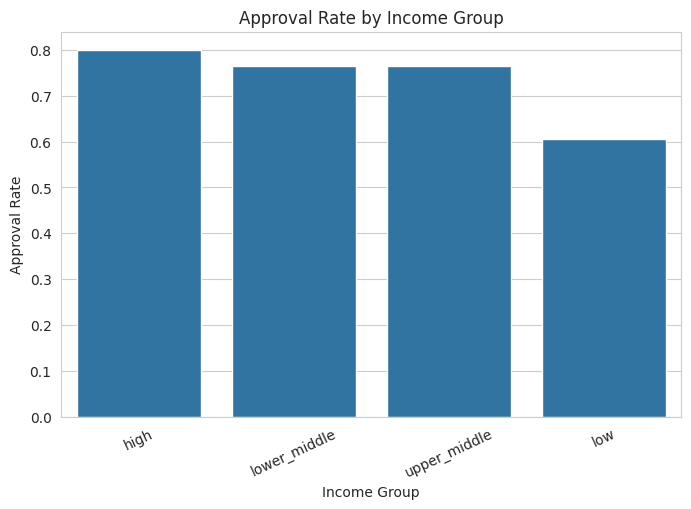

In [16]:
plt.figure(figsize=(8, 5))
sns.barplot(data=income_fairness, x="group", y="approval_rate")
plt.title("Approval Rate by Income Group")
plt.ylabel("Approval Rate")
plt.xlabel("Income Group")
plt.xticks(rotation=25)
plt.show()

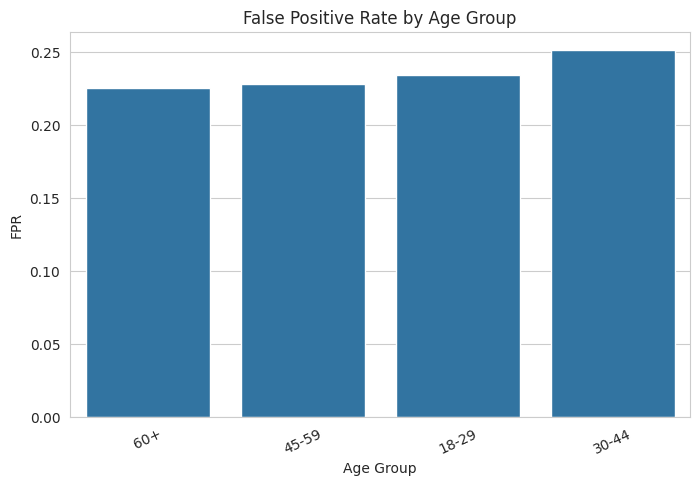

In [17]:
plt.figure(figsize=(8, 5))
sns.barplot(data=age_fairness, x="group", y="fpr")
plt.title("False Positive Rate by Age Group")
plt.ylabel("FPR")
plt.xlabel("Age Group")
plt.xticks(rotation=25)
plt.show()

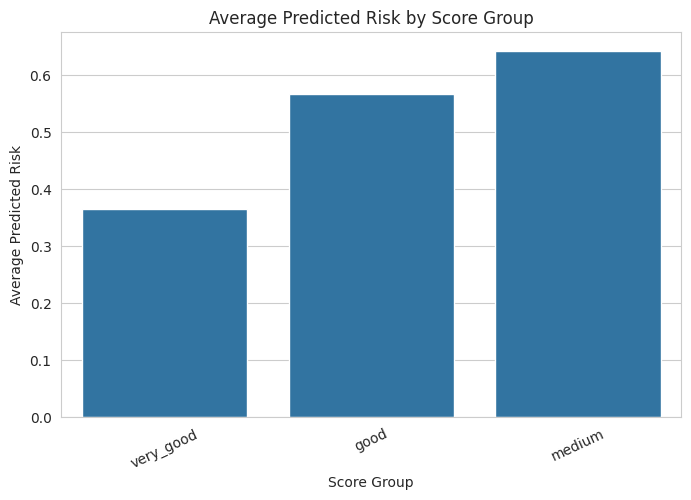

In [18]:
plt.figure(figsize=(8, 5))
sns.barplot(data=score_fairness, x="group", y="avg_pred_risk")
plt.title("Average Predicted Risk by Score Group")
plt.ylabel("Average Predicted Risk")
plt.xlabel("Score Group")
plt.xticks(rotation=25)
plt.show()

## 12. Spezialfall: hohes Einkommen, aber schwacher Score
Hier prüfen wir, ob wirtschaftlich starke Personen durch einen schwachen Score möglicherweise benachteiligt werden.

In [19]:
high_income_cutoff = df_eval["net_income"].quantile(0.75)
low_score_cutoff = df_eval["new_score"].quantile(0.25)

df_eval["potentially_excluded"] = (
    (df_eval["net_income"] >= high_income_cutoff) &
    (df_eval["new_score"] <= low_score_cutoff)
).astype(int)

excluded_group = df_eval[df_eval["potentially_excluded"] == 1].copy()

excluded_summary = pd.DataFrame([{
    "count": len(excluded_group),
    "approval_rate": excluded_group["approved"].mean() if len(excluded_group) > 0 else np.nan,
    "actual_default_rate": excluded_group["actual_default"].mean() if len(excluded_group) > 0 else np.nan,
    "avg_income": excluded_group["net_income"].mean() if len(excluded_group) > 0 else np.nan,
    "avg_old_score": excluded_group["old_score"].mean() if len(excluded_group) > 0 else np.nan,
    "avg_new_score": excluded_group["new_score"].mean() if len(excluded_group) > 0 else np.nan,
    "avg_pred_risk": excluded_group["pred_proba"].mean() if len(excluded_group) > 0 else np.nan
}])

excluded_summary

,count,approval_rate,actual_default_rate,avg_income,avg_old_score,avg_new_score,avg_pred_risk
0,500,0.8000,0.1260,"4,655.2737",86.1790,96.9570,0.3378


In [20]:
excluded_group[[
    "net_income",
    "old_score",
    "new_score",
    "pred_proba",
    "approved",
    "actual_default"
]].head(10)

,net_income,old_score,new_score,pred_proba,approved,actual_default
7410,"4,151.7200",93.8000,100.0000,0.1709,1,0
9042,"5,377.8900",100.0000,100.0000,0.4664,1,0
9363,"5,201.3800",85.3000,100.0000,0.3584,1,1
3482,"3,853.0600",89.7000,100.0000,0.5776,0,0
4386,"4,944.6900",100.0000,100.0000,0.1997,1,0
9468,"4,235.1300",100.0000,100.0000,0.1558,1,1
7763,"4,734.7700",100.0000,100.0000,0.2362,1,0
8342,"4,053.2600",100.0000,100.0000,0.1077,1,0
899,"4,309.6000",69.4000,100.0000,0.6128,0,1
9235,"4,722.2800",85.6000,100.0000,0.0882,1,0


## 13. Business-Impact-Modell
Wir bewerten die Entscheidungen wirtschaftlich.

### Annahmen
- Genehmigt + kein Default = Gewinn
- Genehmigt + Default = Verlust
- Abgelehnt + eigentlich guter Kunde = Opportunitätskosten
- Abgelehnt + tatsächlicher Default = kein Verlust

In [21]:
avg_margin_rate = 0.12
loss_given_default = 0.60
opportunity_cost_rate = 0.08

def calculate_business_impact(df_in, approved_col="approved", default_col="actual_default", loan_col="credit_amount"):
    temp = df_in.copy()
    temp["profit"] = 0.0

    temp.loc[
        (temp[approved_col] == 1) & (temp[default_col] == 0),
        "profit"
    ] = temp[loan_col] * avg_margin_rate

    temp.loc[
        (temp[approved_col] == 1) & (temp[default_col] == 1),
        "profit"
    ] = -temp[loan_col] * loss_given_default

    temp.loc[
        (temp[approved_col] == 0) & (temp[default_col] == 0),
        "profit"
    ] = -temp[loan_col] * opportunity_cost_rate

    temp.loc[
        (temp[approved_col] == 0) & (temp[default_col] == 1),
        "profit"
    ] = 0.0

    return temp

In [22]:
df_business = calculate_business_impact(df_eval)

total_profit = df_business["profit"].sum()
avg_profit = df_business["profit"].mean()
approval_rate_total = df_business["approved"].mean()

approved_subset = df_business[df_business["approved"] == 1]
default_rate_approved = approved_subset["actual_default"].mean() if len(approved_subset) > 0 else np.nan

print("Total Profit:", round(total_profit, 2))
print("Average Profit per Applicant:", round(avg_profit, 2))
print("Approval Rate:", round(approval_rate_total, 4))
print("Default Rate among Approved:", round(default_rate_approved, 4))

Total Profit: 272216.48
Average Profit per Applicant: 136.11
Approval Rate: 0.7345
Default Rate among Approved: 0.0946


## 14. Business Impact nach Einkommensgruppen

In [23]:
group_profit = df_business.groupby("income_group").agg(
    applicants=("profit", "count"),
    total_profit=("profit", "sum"),
    avg_profit=("profit", "mean"),
    approval_rate=("approved", "mean"),
    default_rate=("actual_default", "mean")
).reset_index()

group_profit

,income_group,applicants,total_profit,avg_profit,approval_rate,default_rate
0,low,500,"-40,189.3716",-80.3787,0.6060,0.2020
1,lower_middle,500,"95,999.5768",191.9992,0.7660,0.1000
2,upper_middle,500,"142,385.9428",284.7719,0.7660,0.0920
3,high,500,"74,020.3288",148.0407,0.8000,0.1260


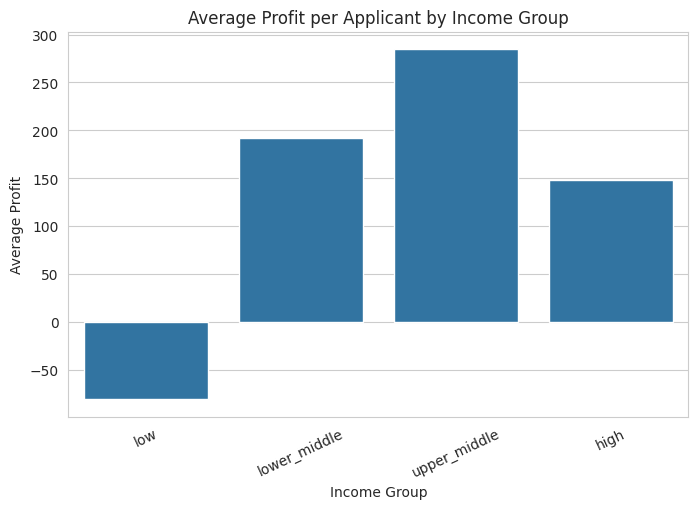

In [24]:
plt.figure(figsize=(8, 5))
sns.barplot(data=group_profit, x="income_group", y="avg_profit")
plt.title("Average Profit per Applicant by Income Group")
plt.ylabel("Average Profit")
plt.xlabel("Income Group")
plt.xticks(rotation=25)
plt.show()

## 15. Strategievergleich
Wir vergleichen:
- Old Score
- New Score
- ML-Modell

In [26]:
df_strategy = df_eval.copy()

df_strategy["approved_old_score"] = (df_strategy["old_score"] >= 70).astype(int)
df_strategy["approved_new_score"] = (df_strategy["new_score"] >= 70).astype(int)
df_strategy["approved_model"] = df_strategy["approved"]

In [27]:
def evaluate_strategy(df_in, approval_col, strategy_name):
    temp = df_in.copy()
    temp["approved"] = temp[approval_col]
    temp = calculate_business_impact(temp)

    approved_subset = temp[temp["approved"] == 1]
    default_rate_approved = approved_subset["actual_default"].mean() if len(approved_subset) > 0 else np.nan

    fairness_table = fairness_metrics_by_group(temp, "income_group")
    income_approval_gap = fairness_table["approval_rate"].max() - fairness_table["approval_rate"].min()

    return {
        "strategy": strategy_name,
        "approval_rate": temp["approved"].mean(),
        "default_rate_approved": default_rate_approved,
        "total_profit": temp["profit"].sum(),
        "avg_profit": temp["profit"].mean(),
        "income_approval_gap": income_approval_gap
    }

strategy_results = pd.DataFrame([
    evaluate_strategy(df_strategy, "approved_old_score", "Old Score"),
    evaluate_strategy(df_strategy, "approved_new_score", "New Score"),
    evaluate_strategy(df_strategy, "approved_model", "ML Model")
])

strategy_results.sort_values("total_profit", ascending=False).reset_index(drop=True)

,strategy,approval_rate,default_rate_approved,total_profit,avg_profit,income_approval_gap
0,New Score,0.9835,0.1276,"579,406.2628",289.7031,0.0180
1,Old Score,0.8540,0.1095,"578,604.6448",289.3023,0.1100
2,ML Model,0.7345,0.0946,"272,216.4768",136.1082,0.1940


## 16. Threshold-Szenarien simulieren
Hier prüfen wir, wie sich Fairness und Profitabilität bei unterschiedlichen Entscheidungsschwellen verändern.

In [28]:
thresholds = np.arange(0.20, 0.81, 0.05)

scenario_results = []

for t in thresholds:
    temp = df_eval.copy()
    temp["approved"] = (temp["pred_proba"] < t).astype(int)
    temp["pred_label"] = (temp["pred_proba"] >= t).astype(int)

    temp = calculate_business_impact(temp)

    approved_subset = temp[temp["approved"] == 1]
    approved_default_rate = approved_subset["actual_default"].mean() if len(approved_subset) > 0 else np.nan

    fairness_table = fairness_metrics_by_group(temp, "income_group")
    approval_gap = fairness_table["approval_rate"].max() - fairness_table["approval_rate"].min()

    scenario_results.append({
        "threshold": t,
        "approval_rate": temp["approved"].mean(),
        "total_profit": temp["profit"].sum(),
        "avg_profit": temp["profit"].mean(),
        "approved_default_rate": approved_default_rate,
        "income_approval_gap": approval_gap
    })

scenario_df = pd.DataFrame(scenario_results)
scenario_df

,threshold,approval_rate,total_profit,avg_profit,approved_default_rate,income_approval_gap
0,0.2000,0.1480,"-1,080,291.7012",-540.1459,0.0270,0.1820
1,0.2500,0.2290,"-741,403.4432",-370.7017,0.0371,0.2760
2,0.3000,0.3670,"-351,631.7612",-175.8159,0.0559,0.3640
3,0.3500,0.4835,"-84,743.0272",-42.3715,0.0620,0.3680
4,0.4000,0.5770,"47,075.1088",23.5376,0.0702,0.2580
5,0.4500,0.6485,"175,938.8168",87.9694,0.0779,0.2180
6,0.5000,0.7345,"272,216.4768",136.1082,0.0946,0.1940
7,0.5500,0.8385,"609,972.4528",304.9862,0.1049,0.2120
8,0.6000,0.9170,"626,153.7928",313.0769,0.1140,0.1720
9,0.6500,0.9560,"623,821.3948",311.9107,0.1198,0.1160


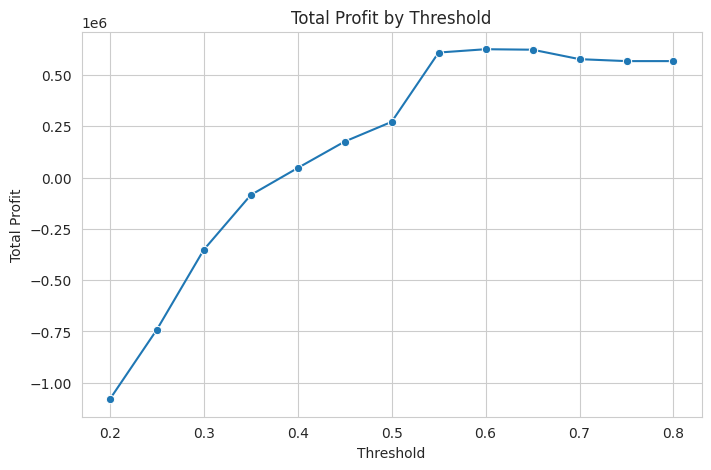

In [29]:
plt.figure(figsize=(8, 5))
sns.lineplot(data=scenario_df, x="threshold", y="total_profit", marker="o")
plt.title("Total Profit by Threshold")
plt.ylabel("Total Profit")
plt.xlabel("Threshold")
plt.show()

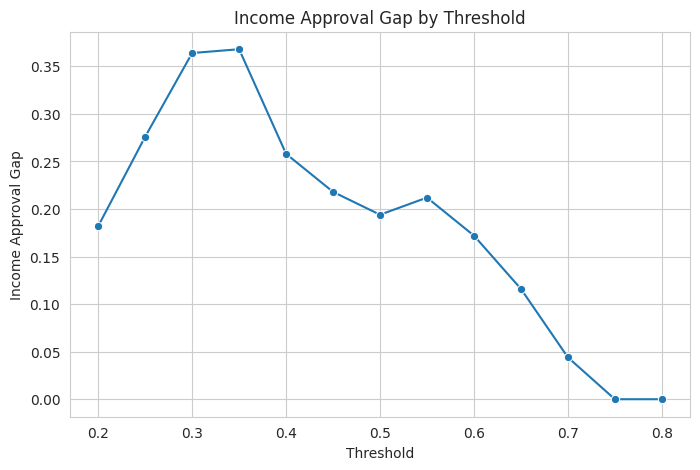

In [30]:
plt.figure(figsize=(8, 5))
sns.lineplot(data=scenario_df, x="threshold", y="income_approval_gap", marker="o")
plt.title("Income Approval Gap by Threshold")
plt.ylabel("Income Approval Gap")
plt.xlabel("Threshold")
plt.show()

## 17. Zentrale Ergebnisse zusammenfassen
Wir erstellen eine kompakte Übersicht der wichtigsten Kennzahlen.

In [31]:
summary_table = pd.DataFrame({
    "metric": [
        "best_model",
        "test_roc_auc",
        "approval_rate",
        "default_rate_among_approved",
        "total_profit",
        "avg_profit_per_applicant",
        "largest_income_group_gap"
    ],
    "value": [
        best_model_name,
        comparison.loc[0, "ROC_AUC"],
        df_business["approved"].mean(),
        default_rate_approved,
        df_business["profit"].sum(),
        df_business["profit"].mean(),
        income_fairness["approval_rate"].max() - income_fairness["approval_rate"].min()
    ]
})

summary_table

,metric,value
0,best_model,Random Forest
1,test_roc_auc,0.6998
2,approval_rate,0.7345
3,default_rate_among_approved,0.0946
4,total_profit,"272,216.4768"
5,avg_profit_per_applicant,136.1082
6,largest_income_group_gap,0.1940


# Fazit

Dieses Notebook zeigt, dass die Bewertung eines Kreditmodells nicht bei Accuracy oder ROC-AUC enden sollte.

## Zentrale Erkenntnisse
- Modellentscheidungen können zwischen Gruppen deutlich unterschiedlich ausfallen.
- Bestimmte Gruppen könnten seltener genehmigt werden oder höhere Fehlerraten aufweisen.
- Ein Modell kann technisch gut sein, aber wirtschaftlich oder fairness-bezogen problematisch eingestellt sein.
- Die Wahl des Schwellenwerts beeinflusst Profitabilität und Fairness gleichzeitig.
- Besonders relevant ist der Fall von Personen mit hohem Einkommen, aber schwachem Score, die möglicherweise zu streng behandelt werden.

## Bedeutung für das Projekt
Damit verbindet dieses Notebook:
- Machine Learning
- Kreditrisikoanalyse
- Business-Verständnis
- Fairness-Perspektive

Genau diese Kombination macht das Projekt stark und praxisnah.

In [32]:
income_fairness.to_csv("income_fairness.csv", index=False)
age_fairness.to_csv("age_fairness.csv", index=False)
score_fairness.to_csv("score_fairness.csv", index=False)
strategy_results.to_csv("strategy_results.csv", index=False)
scenario_df.to_csv("threshold_scenarios.csv", index=False)
summary_table.to_csv("fairness_business_summary.csv", index=False)

print("CSV-Dateien wurden exportiert.")

CSV-Dateien wurden exportiert.
